In [55]:

# Customer Churn Prediction

print("===================================")
print(" CUSTOMER CHURN PREDICTION PROJECT")
print("===================================")

print("Project Status: Started")
print("Programming Language: Python")
print("Environment: Jupyter Notebook")
print("Machine Learning: Classification")

print("\nProject setup completed successfully!")


 CUSTOMER CHURN PREDICTION PROJECT
Project Status: Started
Programming Language: Python
Environment: Jupyter Notebook
Machine Learning: Classification

Project setup completed successfully!


In [56]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import joblib

print("All libraries imported successfully!")

print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)


All libraries imported successfully!
Pandas Version: 3.0.3
NumPy Version: 2.4.4
Scikit-learn Version: 1.9.0


In [57]:
#  Load Dataset

import pandas as pd

file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [58]:

# Understanding the Dataset

print("Total Rows and Columns:")
print(df.shape)

print("\nAll Column Names:")
print(df.columns.tolist())

Total Rows and Columns:
(7043, 21)

All Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [59]:

# Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [60]:

# Statistical Summary

df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [61]:

# Check Churn Distribution

print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [62]:

# Check Duplicate Records

print("Total Duplicate Rows:",
      df.duplicated().sum())


Total Duplicate Rows: 0


In [63]:

# Check Missing Values

print("Missing Values in Each Column:")

print(df.isnull().sum())


Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [64]:

#  Convert TotalCharges to Numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges Data Type:")
print(df["TotalCharges"].dtype)

print("\nMissing Values in TotalCharges:")
print(df["TotalCharges"].isnull().sum())


TotalCharges Data Type:
float64

Missing Values in TotalCharges:
11


In [65]:

#  Final Data Quality Check

print("Dataset Shape:", df.shape)

print("\nTotal Duplicate Rows:",
      df.duplicated().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("\nUpdated Data Types:")
print(df.dtypes)


Dataset Shape: (7043, 21)

Total Duplicate Rows: 0

Total Missing Values: 11

Updated Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [66]:

#  Handle Missing Values

# Check customers with missing TotalCharges
print(df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "TotalCharges"]
])

# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

print("\nUpdated TotalCharges Data Type:")
print(df["TotalCharges"].dtype)

      customerID  tenure  TotalCharges
488   4472-LVYGI       0           NaN
753   3115-CZMZD       0           NaN
936   5709-LVOEQ       0           NaN
1082  4367-NUYAO       0           NaN
1340  1371-DWPAZ       0           NaN
3331  7644-OMVMY       0           NaN
3826  3213-VVOLG       0           NaN
4380  2520-SGTTA       0           NaN
5218  2923-ARZLG       0           NaN
6670  4075-WKNIU       0           NaN
6754  2775-SEFEE       0           NaN

Missing Values After Cleaning:
0

Updated TotalCharges Data Type:
float64


In [67]:

# Final Data Cleaning Verification

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Duplicate Rows:", df.duplicated().sum())

print("Missing Values:", df.isnull().sum().sum())

print("\nData Cleaning Completed Successfully!")


Total Rows: 7043
Total Columns: 21
Duplicate Rows: 0
Missing Values: 0

Data Cleaning Completed Successfully!


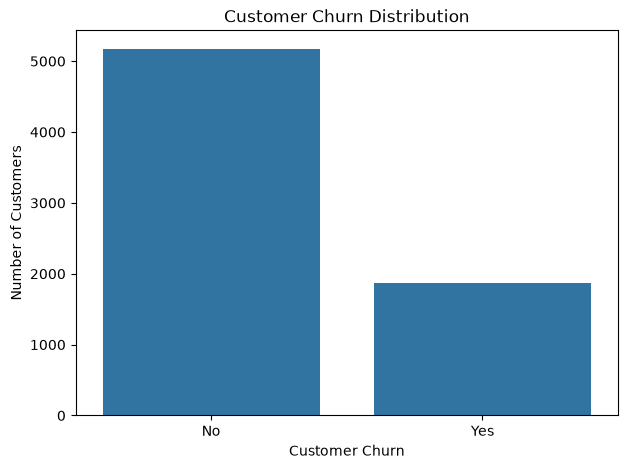

In [68]:

# Graph: Customer Churn Distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

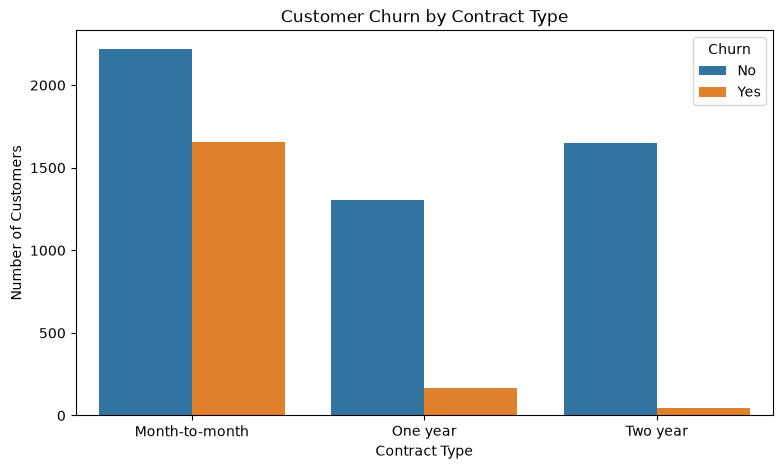

In [69]:

# Graph : Churn by Contract Type

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()


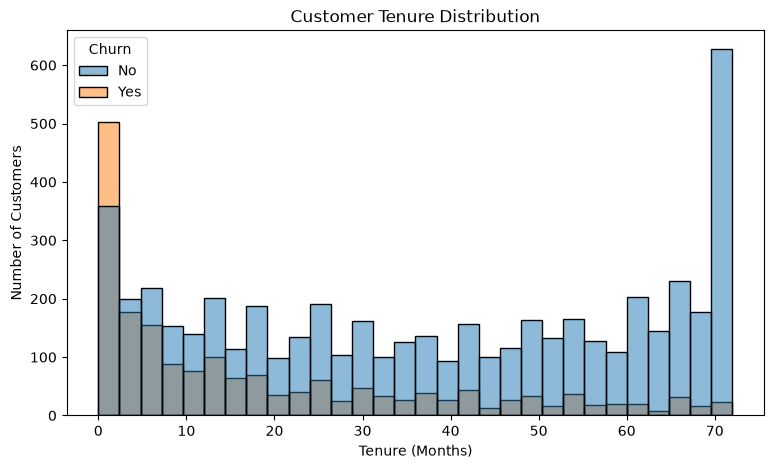

In [70]:

# Graph : Customer Tenure Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer"
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


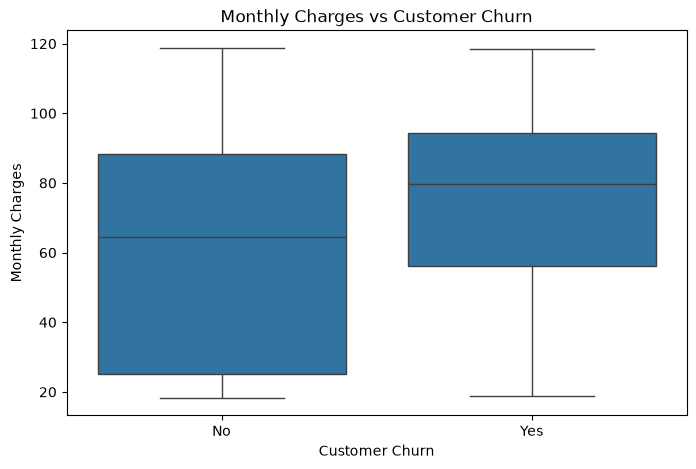

In [71]:

# Graph : Monthly Charges vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()


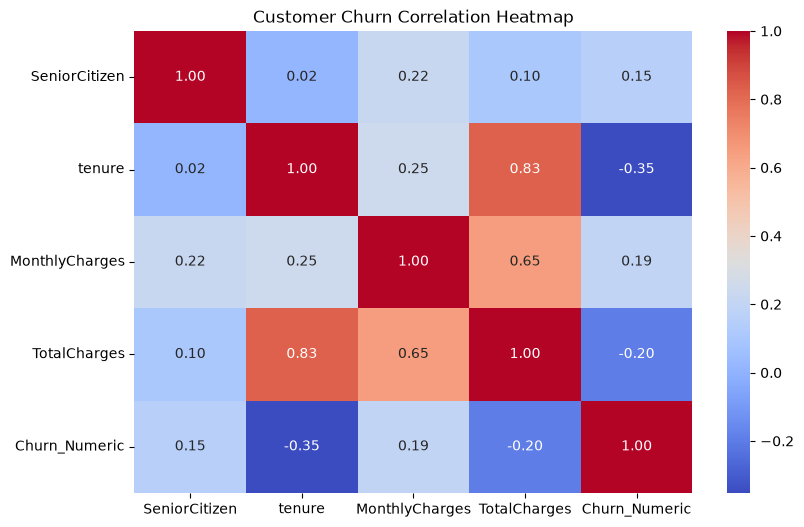

In [72]:

# Graph : Correlation Heatmap

df["Churn_Numeric"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

numeric_data = df[
    ["SeniorCitizen", "tenure",
     "MonthlyCharges", "TotalCharges",
     "Churn_Numeric"]
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Churn Correlation Heatmap")

plt.show()


In [73]:

#  Separate Features and Target

# Remove unnecessary columns
X = df.drop(
    columns=["customerID", "Churn", "Churn_Numeric"],
    errors="ignore"
)

# Convert target into numerical values
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())


Features Shape: (7043, 19)
Target Shape: (7043,)

Target Values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [74]:

# Identify Column Types

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\DELL\AppData\Local\Temp\ipykernel_13924\1354052788.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [75]:

#  Split Dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Data: (5634, 19)
Testing Data: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


In [76]:

#  Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data After Processing:",
      X_train_processed.shape)

print("Testing Data After Processing:",
      X_test_processed.shape)

print("\nData Preprocessing Completed!")


Training Data After Processing: (5634, 45)
Testing Data After Processing: (1409, 45)

Data Preprocessing Completed!


In [77]:

#  Logistic Regression Model

from sklearn.linear_model import LogisticRegression

# Create Model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train Model
lr_model.fit(X_train_processed, y_train)

# Make Predictions
lr_predictions = lr_model.predict(X_test_processed)

print("Logistic Regression Model Trained Successfully!")

print("Total Predictions:", len(lr_predictions))


Logistic Regression Model Trained Successfully!
Total Predictions: 1409


In [78]:

#  Random Forest Model

from sklearn.ensemble import RandomForestClassifier

# Create Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train Model
rf_model.fit(X_train_processed, y_train)

# Make Predictions
rf_predictions = rf_model.predict(X_test_processed)

print("Random Forest Model Trained Successfully!")

print("Total Predictions:", len(rf_predictions))


Random Forest Model Trained Successfully!
Total Predictions: 1409


In [79]:

# Check Model Predictions

print("Logistic Regression Predictions:")
print(lr_predictions[:10])

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])

print("\nActual Values:")
print(y_test.values[:10])


Logistic Regression Predictions:
[0 1 0 0 0 1 0 0 0 0]

Random Forest Predictions:
[0 1 0 0 0 1 0 0 0 1]

Actual Values:
[0 0 0 0 0 0 0 0 0 1]


In [80]:

# Accuracy Score

from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_predictions)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")


Logistic Regression Accuracy: 80.55 %
Random Forest Accuracy: 77.0 %


In [81]:

# Step 8.2: Classification Report

from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, lr_predictions))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_predictions))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409



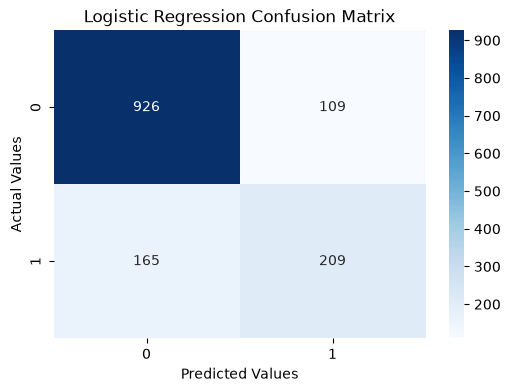

In [82]:

# Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()


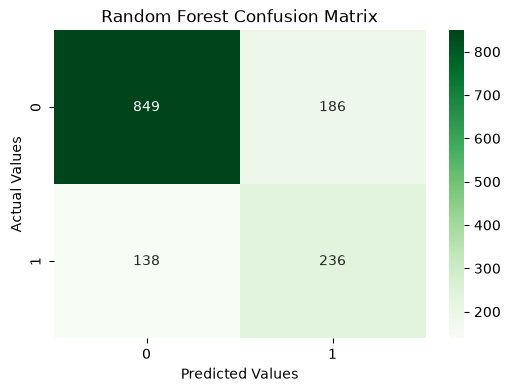

In [83]:

rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()


In [84]:

#  Model Comparison

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        lr_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(model_comparison)

best_model_name = (
    "Logistic Regression"
    if lr_accuracy >= rf_accuracy
    else "Random Forest"
)

print("\nBest Model by Accuracy:", best_model_name)


                 Model   Accuracy
0  Logistic Regression  80.553584
1        Random Forest  77.004968

Best Model by Accuracy: Logistic Regression


In [85]:

#  Select Best Model

from sklearn.metrics import f1_score

lr_f1 = f1_score(y_test, lr_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("Logistic Regression F1:", round(lr_f1, 4))
print("Random Forest F1:", round(rf_f1, 4))

if lr_f1 >= rf_f1:
    best_model = lr_model
    best_model_name = "Logistic Regression"
else:
    best_model = rf_model
    best_model_name = "Random Forest"

print("\nSelected Model:", best_model_name)


Logistic Regression F1: 0.604
Random Forest F1: 0.593

Selected Model: Logistic Regression


In [86]:

#  New Customer Information

new_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 70.70,
    "TotalCharges": 151.65
}

new_customer_df = pd.DataFrame([new_customer])

print(new_customer_df)


   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0      No         No       2          Yes   

  MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection  \
0            No     Fiber optic             No           No               No   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   

      PaymentMethod  MonthlyCharges  TotalCharges  
0  Electronic check            70.7        151.65  


In [87]:

# Predict Customer Churn

# Transform new customer using existing preprocessor
new_customer_processed = preprocessor.transform(
    new_customer_df[X.columns]
)

# Predict churn
prediction = best_model.predict(new_customer_processed)

# Get estimated churn probability
probability = best_model.predict_proba(
    new_customer_processed
)[0][1]

print("Selected Model:", best_model_name)

if prediction[0] == 1:
    print("\nPrediction: Customer May Leave!")
else:
    print("\nPrediction: Customer May Stay!")

print("Estimated Churn Probability:",
      round(probability * 100, 2), "%")


Selected Model: Logistic Regression

Prediction: Customer May Leave!
Estimated Churn Probability: 69.16 %


In [88]:

#  Save Model

import joblib
import os

# Create project folder
os.makedirs("customer_churn_project", exist_ok=True)

# Save model and preprocessor together
joblib.dump(
    {
        "model": best_model,
        "preprocessor": preprocessor,
        "model_name": best_model_name
    },
    "customer_churn_project/churn_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [89]:

#  Load Saved Model

saved_artifacts = joblib.load(
    "customer_churn_project/churn_model.pkl"
)

loaded_model = saved_artifacts["model"]
loaded_preprocessor = saved_artifacts["preprocessor"]

print("Model Loaded Successfully!")
print("Model Name:", saved_artifacts["model_name"])


Model Loaded Successfully!
Model Name: Logistic Regression


In [90]:

#  Test Loaded Model

test_predictions = loaded_model.predict(
    X_test_processed
)

print("Saved Model Accuracy:",
      round(accuracy_score(y_test, test_predictions) * 100, 2),
      "%")

print("Saved Model Tested Successfully!")


Saved Model Accuracy: 80.55 %
Saved Model Tested Successfully!


In [91]:

#  Save Performance Report

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    best_model.predict(X_test_processed),
    target_names=["Stayed", "Churned"]
)

with open(
    "customer_churn_project/model_report.txt",
    "w"
) as file:
    file.write("CUSTOMER CHURN PREDICTION PROJECT\n")
    file.write("================================\n\n")
    file.write("Best Model: " + best_model_name + "\n\n")
    file.write(report)

print("Performance Report Saved Successfully!")


Performance Report Saved Successfully!
